# A8. PC vs 콘솔 가격 차이 — 같은 게임, 어느 플랫폼으로 사야 싼가

* 담당: 김준영 · 분석 방향 문서의 **A8** (11/22 회의 확정)
* 한 줄 질문: **"같은 게임을 PC로 살 때와 콘솔(새 상품)로 살 때 얼마나 차이 나고, 그 차이는 언제·어디서 줄어드나?"**
* 새로 수집한 데이터는 없습니다. **두 출처(ITAD = PC, 다나와 = 콘솔)를 게임 ID(IGDB)로 합친 결과**를 분석합니다. 이것이 이 프로젝트의 "데이터 통합" 결과물입니다.

### 데이터 처리 과정 (이 프로젝트의 수집 → 전달 → 정제 → 저장 → 활용 중 이 노트북이 맡는 부분)

| 단계 | 내용 | 이 노트북에서 |
| --- | --- | --- |
| 수집 | ITAD(PC 스토어 가격), 다나와(콘솔 패키지 가격) | 이미 수집기가 `raw.*`로 전송 |
| 전달·정제 | Kafka → 정제 프로그램: 중복 제거, **원화 환산**, **게임 ID 통합** (스토어 상품 → IGDB `game_id`) | 이미 `refined.prices`로 정제됨 |
| 저장 | Kafka Connect → MariaDB `prices_current` (게임·스토어·에디션·플랫폼·상태별 현재가) | SQL로 읽기 전용 추출한 TSV를 불러옴 |
| 활용 | PC·콘솔 가격 쌍 만들기 → 격차 계산 → 가설 검정 → 인사이트 | 3~8장 |

### 분석 순서
1. 환경 설정 → 2. **가설 설정** → 3. 데이터 불러오기·점검 → 4. 전처리(가격 쌍 만들기) → 5. 탐색(EDA) → 6. **통계 검정** → 7. 의미 있는 결과인가? → 8. **인사이트·제안**

> 이 노트북의 숫자는 모두 실행 결과로 계산됩니다. 해설 문장 중 "알 수 있다"는 *무엇을 보는 차트인지* 설명이며, 결론은 7~8장에서 실제 값으로 자동 출력됩니다.

### 준비 (한 번만)
```bash
pip install pandas numpy scipy seaborn matplotlib statsmodels jupyterlab
```
* DB 데이터 추출 (mariadb-re, 읽기 전용 계정):
```bash
mysql -u <읽기 계정> -p gamenuri -B --default-character-set=utf8mb4 < analysis/scripts/a8_extract.sql > analysis/data/a8_prices.tsv
```

## 1. 환경 설정

In [1]:
# 불필요한 경고 메시지를 숨겨 출력이 깔끔하게 보이도록 합니다.
import warnings
warnings.filterwarnings('ignore')

In [2]:
# 분석에 필요한 라이브러리를 불러옵니다.
# pandas/numpy: 데이터 처리, scipy/statsmodels: 통계 검정·회귀, matplotlib/seaborn: 시각화
import os, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

%matplotlib inline

### 한글 폰트 설정

In [3]:
# 그래프의 한글이 깨지지 않도록 설치된 한글 폰트를 찾아 지정합니다. (Windows: 맑은 고딕, Mac: AppleGothic)
candidates = ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)

plt.rcParams['font.family'] = font_name or 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid', {'font.family': plt.rcParams['font.family']})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

BLUE, ORANGE, GRAY, GREEN = '#2a78d6', '#eb6834', '#a3a29d', '#2f9e6e'
print('사용 폰트:', font_name)

사용 폰트: Malgun Gothic


## 2. 가설 설정

데이터를 보기 **전에** 가설과 판정 기준을 먼저 정해 둡니다.

**격차(gap) = (콘솔 새 상품 최저가 − PC 새 상품 최저가) ÷ PC 최저가.** +이면 콘솔이 더 비쌉니다. 한 게임에 콘솔이 여러 개(PS5, Switch …)면 플랫폼마다 한 쌍씩 만듭니다.

| # | 가설 (H1: 우리가 기대하는 것) | 귀무가설 (H0) | 통계 도구 | 실무 기준 ("의미 있다"의 조건) |
| --- | --- | --- | --- | --- |
| H1 | **콘솔 새 상품은 PC보다 비싸다** | 가격 차이의 중앙값이 0이다 | Shapiro-Wilk로 정규성 확인 → **Wilcoxon 부호순위**(단측), 게임 단위 부트스트랩 신뢰구간 | 중앙값 +10% 이상 |
| H2 | **출시 후 오래될수록 격차가 줄어든다** | 경과 기간과 격차는 관계가 없다 | **Spearman 상관**(단측), **Kruskal-Wallis**, 구간별 Wilcoxon (**Holm 보정**), **회귀분석**(다른 요인 통제) | 오래된 구간의 격차가 신작 구간보다 5%p 이상 작음 |
| H3 | **플랫폼마다 격차가 다르다** | 플랫폼 사이에 격차 차이가 없다 | **Kruskal-Wallis**, 쌍별 **Mann-Whitney U** (Holm 보정) | 가장 큰·작은 플랫폼 중앙값 차이 5%p 이상 |

* **유의수준 α = 0.05.** 통계적으로 유의해도 효과가 작으면 "의미 없음"으로 판정합니다.
* **같은 게임이 여러 콘솔 쌍에 들어가므로 쌍은 독립이 아닙니다.** H1은 게임 단위로 요약해서 검정하고, 신뢰구간은 *게임 단위로 다시 뽑는(cluster bootstrap)* 방식, 회귀는 *게임 단위 군집 표준오차*를 씁니다.

### 분석 설정값 (한 곳에서 관리)

In [4]:
# ---- 데이터 위치 ----
DATA_DIR = Path(os.environ.get('GAMENURI_DATA_DIR', '../data'))     # analysis/data (Git에 올리지 않음)
RESULT_DIR = Path(os.environ.get('GAMENURI_RESULT_DIR', '../results/a8'))
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ---- 분석 정의 ----
RATIO_LIMIT = 4.0           # 콘솔/PC 가격비가 4배를 넘거나 1/4 미만이면 다른 상품이 연결된 것으로 보고 제외
AGE_BINS = [0, 12, 24, 48, 10_000]
AGE_LABELS = ['1년 미만', '1~2년', '2~4년', '4년 이상']
MIN_N = 15                  # 플랫폼·구간 표본이 이보다 적으면 검정하지 않고 "표본 부족"

# ---- 통계 ----
ALPHA = 0.05
PRACTICAL_GAP = 0.10        # H1 실무 기준: 콘솔이 PC보다 10% 이상 비쌈
PRACTICAL_DIFF = 0.05       # H2·H3 실무 기준: 5%p 이상 차이
N_BOOT, SEED = 2000, 42

R = {}                      # 최종 요약에 쓸 결과 저장소

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(RESULT_DIR / name, dpi=150, bbox_inches='tight')

## 3. 데이터 불러오기와 점검

In [6]:
# mysql --batch로 뽑은 TSV를 읽습니다. 값이 없는 칸은 문자열 'NULL'로 나오므로 결측치로 바꿔 줍니다.
path = DATA_DIR / 'a8_prices.tsv'
if not path.exists():
    raise FileNotFoundError(f'{path} 가 없습니다. 위 "준비" 칸의 mysql 명령으로 먼저 추출하세요.')
raw = pd.read_csv(path, sep='\t', na_values=['NULL'], parse_dates=['release_date', 'collected_at'])
print('가격 행:', raw.shape, '/ 게임 수:', raw['game_id'].nunique())
raw.head()

가격 행: (1557, 15) / 게임 수: 159


,game_id,name,name_ko,release_date,game_type,is_online,store,edition,platform,price_krw,regular_krw,discount_pct,collected_at,review_count_ko,genres
0,493,Heavy Rain,헤비 레인,2010-02-18,0,0,epic,digital,PC,1990,"19,900.000",90.000,2026-11-25 15:05:05,342,Adventure
1,493,Heavy Rain,헤비 레인,2010-02-18,0,0,gamersgate,digital,PC,2150,"21,500.000",90.000,2026-11-25 15:05:05,342,Adventure
2,493,Heavy Rain,헤비 레인,2010-02-18,0,0,steam,digital,PC,2150,"21,500.000",90.000,2026-11-25 15:05:05,342,Adventure
3,493,Heavy Rain,헤비 레인,2010-02-18,0,0,gamebillet,digital,PC,2153,"26,905.000",92.000,2026-11-25 15:05:05,342,Adventure
4,493,Heavy Rain,헤비 레인,2010-02-18,0,0,playsum,digital,PC,2153,"21,521.000",90.000,2026-11-25 15:05:05,342,Adventure


In [7]:
# 데이터 타입과 결측치를 확인합니다. 분석 전에 반드시 구조를 점검하는 단계입니다.
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1557 entries, 0 to 1556
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   game_id          1557 non-null   int64         
 1   name             1557 non-null   str           
 2   name_ko          1444 non-null   str           
 3   release_date     1557 non-null   datetime64[us]
 4   game_type        1557 non-null   int64         
 5   is_online        1557 non-null   int64         
 6   store            1557 non-null   str           
 7   edition          1557 non-null   str           
 8   platform         1557 non-null   str           
 9   price_krw        1557 non-null   int64         
 10  regular_krw      1354 non-null   float64       
 11  discount_pct     1354 non-null   float64       
 12  collected_at     1557 non-null   datetime64[us]
 13  review_count_ko  1557 non-null   int64         
 14  genres           1557 non-null   str           
dty

In [8]:
# 컬럼별 결측치. regular_krw·discount_pct는 콘솔(다나와)에는 없는 값이라 비어 있는 것이 정상입니다.
pd.DataFrame({'결측 수': raw.isnull().sum(), '결측률(%)': raw.isnull().mean() * 100})

,결측 수,결측률(%)
game_id,0,0.000
name,0,0.000
name_ko,113,7.258
release_date,0,0.000
game_type,0,0.000
is_online,0,0.000
store,0,0.000
edition,0,0.000
platform,0,0.000
price_krw,0,0.000


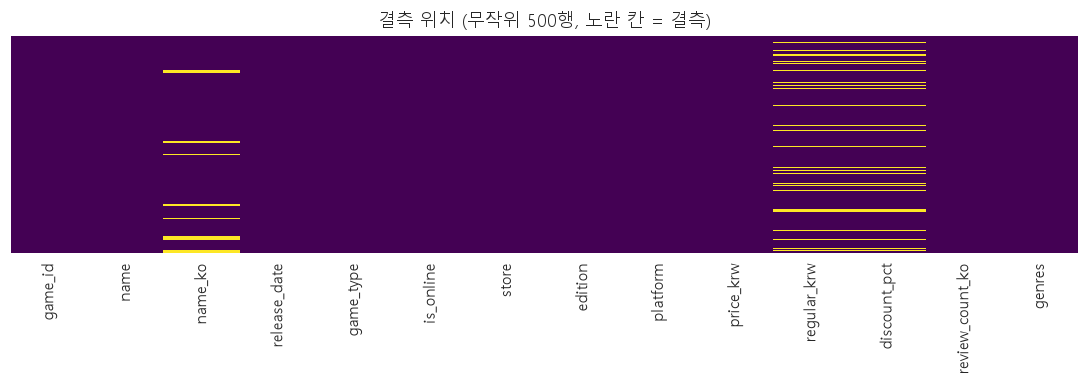

In [9]:
# 결측 위치를 그림으로 확인 (노란 칸 = 결측). 플랫폼별로 어떤 칸이 비는지 봅니다.
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(raw.sort_values('platform').drop(columns=['collected_at']).isnull().sample(min(len(raw), 500), random_state=SEED).sort_index(),
            cbar=False, yticklabels=False, cmap='viridis', ax=ax)
ax.set_title('결측 위치 (무작위 500행, 노란 칸 = 결측)')
savefig(fig, 'a8_0_missing.png'); plt.show()

### 차트 해설
각 행(가격 한 줄)의 컬럼별 결측 위치입니다. 노란 칸이 비어 있는 값입니다.

### 이 차트로 알 수 있는 것
- `regular_krw`(정가)·`discount_pct`(할인율)가 비어 있는 행이 콘솔 행에 몰려 있는지 확인합니다. 다나와는 정가·할인율이 없으므로 **콘솔은 "현재 최저가"로만 비교**할 수 있습니다. (PC는 정가도 있어 7장에서 따로 활용)
- 가격(`price_krw`)·게임 ID·플랫폼에 결측이 없는지 확인합니다. 있으면 분석에서 제외해야 합니다.

In [10]:
# 숫자 컬럼의 기초 통계: 가격이 0 이하이거나 비정상적으로 큰 값이 없는지 확인합니다.
raw[['price_krw', 'regular_krw', 'discount_pct', 'review_count_ko']].describe()

,price_krw,regular_krw,discount_pct,review_count_ko
count,"1,557.000","1,354.000","1,354.000","1,557.000"
mean,"32,433.242","57,863.797",47.572,"2,812.353"
std,"26,000.472","21,237.783",33.953,"4,425.624"
min,0.000,0.000,0.000,201.000
25%,"11,810.000","40,523.000",10.000,381.000
50%,"25,022.000","59,736.000",57.500,"1,187.000"
75%,"47,310.000","74,950.000",78.000,"2,950.000"
max,"188,100.000","125,400.000",96.000,"25,890.000"


,가격행,게임수,가격중앙값
platform,,,
PC,1289,159,"20,211.000"
PS5,76,74,"39,795.000"
PS4,70,69,"34,505.000"
Switch,41,41,"47,310.000"
XboxSeries,36,36,"76,950.000"
XboxOne,28,24,"47,795.000"
Switch2,17,17,"43,065.000"


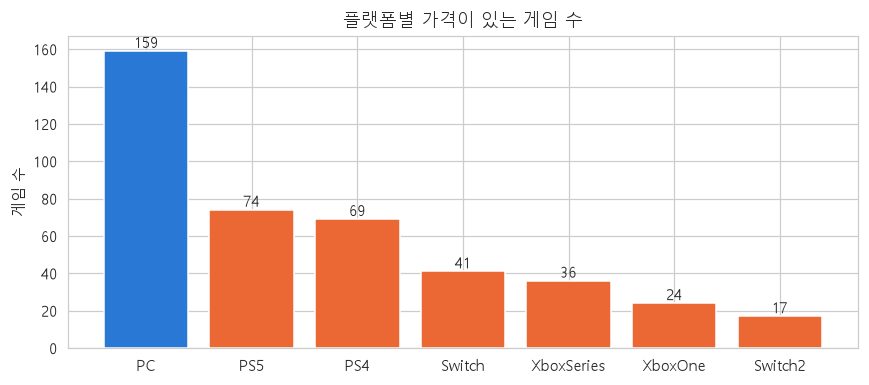

In [11]:
# 플랫폼별 가격 행 수·게임 수 = "다나와 상품이 게임에 연결된 정도". 표본 크기를 정하는 가장 중요한 숫자입니다.
cov = raw.groupby('platform').agg(가격행=('price_krw', 'size'), 게임수=('game_id', 'nunique'), 가격중앙값=('price_krw', 'median')).sort_values('게임수', ascending=False)
display(cov)

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if p == 'PC' else ORANGE for p in cov.index]
bars = ax.bar(cov.index, cov['게임수'], color=colors)
for b_ in bars:
    ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height(), int(b_.get_height()), ha='center', va='bottom')
ax.set_title('플랫폼별 가격이 있는 게임 수'); ax.set_ylabel('게임 수')
savefig(fig, 'a8_1_coverage.png'); plt.show()

### 차트 해설
플랫폼별로 새 상품 가격이 있는 게임이 몇 개인지 보여 줍니다. 파랑은 PC(ITAD), 주황은 콘솔(다나와)입니다.

### 이 차트로 알 수 있는 것
- 콘솔 플랫폼마다 **표본 크기가 얼마나 다른지** 확인합니다. 표본이 `MIN_N`(15)개 미만인 플랫폼은 H3 검정에서 빠집니다.
- 이 분석은 PC와 콘솔 가격이 **모두 있는 게임**만 비교할 수 있으므로, 다나와 상품명이 게임에 연결된 정도가 표본의 한계입니다. 낮다면 별칭(`game_aliases`) 보강이 필요하다는 근거가 됩니다.

## 4. 전처리 — PC·콘솔 가격 쌍 만들기

한 게임에는 스토어·에디션마다 가격이 여러 개 있습니다. 소비자가 보는 가격은 *가장 싼 곳*이므로 다음 순서로 정리합니다.

1. **PC 최저가**: 게임마다 PC 새 상품 중 가장 싼 값 (스토어·에디션 무관) + 그때의 정가·할인율
2. **콘솔 최저가**: 게임×플랫폼마다 새 상품 중 가장 싼 값
3. 두 표를 `game_id`로 합쳐 **(게임, 콘솔 플랫폼) 한 쌍 = 한 행**으로 만들고 격차를 계산
4. **의심 쌍 제거**: 콘솔/PC 가격비가 4배를 넘거나 1/4 미만이면 다른 상품(번들·잘못 연결)일 가능성이 커서 제외
5. 출시일이 없는 게임은 경과 기간을 알 수 없어 제외

In [12]:
d = raw[(raw['price_krw'] > 0)].copy()            # 가격이 0 이하인 행은 오류로 보고 제외
# --- 1) PC 최저가 (+ 그때의 정가·할인율·스토어)
pc = (d[d['platform'] == 'PC'].sort_values(['game_id', 'price_krw'])
        .groupby('game_id').first()[['price_krw', 'regular_krw', 'discount_pct', 'store', 'edition']]
        .add_prefix('pc_'))
# --- 2) 콘솔 최저가 (게임 × 플랫폼)
con = (d[d['platform'] != 'PC'].sort_values(['game_id', 'platform', 'price_krw'])
         .groupby(['game_id', 'platform']).first()[['price_krw', 'store', 'edition']]
         .add_prefix('con_').reset_index())
# --- 게임 정보 (게임당 한 줄)
info = d.groupby('game_id').first()[['name', 'name_ko', 'release_date', 'is_online', 'genres', 'review_count_ko']]

pairs = con.merge(pc, left_on='game_id', right_index=True).merge(info, left_on='game_id', right_index=True)
pairs['label'] = pairs['name_ko'].fillna(pairs['name'])
print('(게임, 콘솔) 쌍:', len(pairs), '/ 게임', pairs['game_id'].nunique(), '개')
pairs.head()

(게임, 콘솔) 쌍: 255 / 게임 149 개


,game_id,platform,con_price_krw,con_store,con_edition,pc_price_krw,pc_regular_krw,pc_discount_pct,pc_store,pc_edition,name,name_ko,release_date,is_online,genres,review_count_ko,label
0,493,PS4,79800,danawa,physical,1990,"19,900.000",90.000,epic,digital,Heavy Rain,헤비 레인,2010-02-18,0,Adventure,342,헤비 레인
1,979,XboxSeries,84500,danawa,code,27950,"55,900.000",50.000,steam,digital,Call of Duty: Modern Warfare 3,콜 오브 듀티: 모던 워페어 3,2011-11-08,1,Adventure|Shooter|Tactical,440,콜 오브 듀티: 모던 워페어 3
2,1081,XboxSeries,67400,danawa,code,5500,"22,000.000",75.000,steam,digital,The Elder Scrolls Online,엘더 스크롤 온라인,2014-04-04,1,Adventure|Role-playing (RPG),922,엘더 스크롤 온라인
3,1164,PS4,28000,danawa,physical,2005,"26,905.000",93.000,wingamestore,digital,Tomb Raider,툼 레이더,2013-03-05,1,Adventure|Platform|Puzzle|Shooter,4162,툼 레이더
4,1164,XboxOne,21900,danawa,code,2005,"26,905.000",93.000,wingamestore,digital,Tomb Raider,툼 레이더,2013-03-05,1,Adventure|Platform|Puzzle|Shooter,4162,툼 레이더


분석 쌍 151개 / 게임 97개


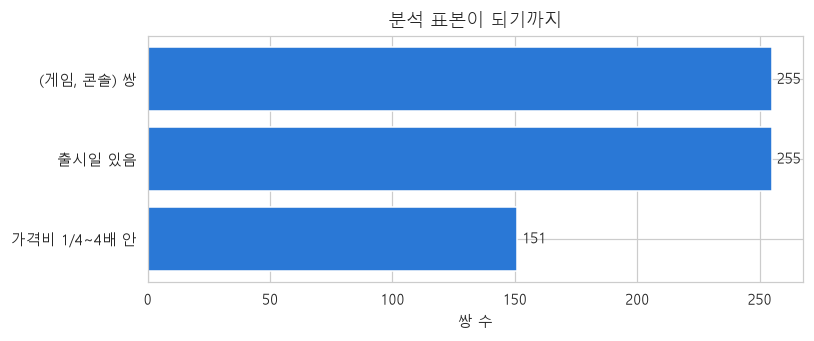

In [13]:
# --- 3) 격차 계산
pairs['ratio'] = pairs['con_price_krw'] / pairs['pc_price_krw']
pairs['gap'] = pairs['ratio'] - 1                          # +0.25 = 콘솔이 25% 비쌈
pairs['log_ratio'] = np.log(pairs['ratio'])                # 비율 자료는 로그로 바꾸면 대칭이 되어 통계가 안정적
pairs['gap_regular'] = pairs['con_price_krw'] / pairs['pc_regular_krw'] - 1       # PC "정가" 대비 (PC 할인을 빼고 본 격차)
pairs['pc_on_sale'] = (pairs['pc_discount_pct'].fillna(0) >= 10).astype(int)       # PC가 지금 할인 중인가
pairs['is_online'] = pairs['is_online'].fillna(0).astype(int)

# --- 4~5) 걸러내기 + 단계별 남는 수
today = pd.Timestamp.now(tz='Asia/Seoul').normalize().tz_localize(None)
funnel = {'(게임, 콘솔) 쌍': len(pairs)}
df = pairs[pairs['release_date'].notna()]
funnel['출시일 있음'] = len(df)
df = df[df['ratio'].between(1 / RATIO_LIMIT, RATIO_LIMIT)].copy()
funnel[f'가격비 1/{RATIO_LIMIT:.0f}~{RATIO_LIMIT:.0f}배 안'] = len(df)
df['age_months'] = ((today - df['release_date']).dt.days / 30.44).clip(lower=0)
df['age_bin'] = pd.cut(df['age_months'], bins=AGE_BINS, labels=AGE_LABELS, right=False)
print(f'분석 쌍 {len(df)}개 / 게임 {df["game_id"].nunique()}개')

fn = pd.Series(funnel)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ax.barh(fn.index[::-1], fn.values[::-1], color=BLUE)
for b_, v in zip(bars, fn.values[::-1]):
    ax.text(v, b_.get_y() + b_.get_height() / 2, f' {v}', va='center')
ax.set_title('분석 표본이 되기까지'); ax.set_xlabel('쌍 수')
savefig(fig, 'a8_2_funnel.png'); plt.show()
R['n_pairs'], R['n_games'] = len(df), int(df['game_id'].nunique())

In [14]:
# 제외된 의심 쌍을 직접 눈으로 확인합니다. 이름이 비슷한 다른 상품(번들·DLC)이 연결된 것인지 판단하는 단계입니다.
sus = pairs[pairs['release_date'].notna() & ~pairs['ratio'].between(1 / RATIO_LIMIT, RATIO_LIMIT)]
print(f'제외된 의심 쌍: {len(sus)}개  (한도 RATIO_LIMIT={RATIO_LIMIT:g}배)')
sus[['label', 'platform', 'pc_price_krw', 'con_price_krw', 'ratio', 'con_store']].sort_values('ratio').head(10)

제외된 의심 쌍: 104개  (한도 RATIO_LIMIT=4배)


,label,platform,pc_price_krw,con_price_krw,ratio,con_store
131,디아블로 IV,XboxSeries,62400,8700,0.139,danawa
171,칼리스토 프로토콜,PS5,63000,10800,0.171,danawa
180,소닉 프론티어,PS4,10440,41800,4.004,danawa
37,바이오하자드 7: 레지던트 이블,XboxOne,9085,36390,4.006,danawa
73,아토믹 하트,PS5,13960,56910,4.077,danawa
221,발라트로,Switch,8515,34800,4.087,danawa
150,잇 테이크 투,PS4,8800,36610,4.160,danawa
10,노 맨즈 스카이,PS4,23460,98700,4.207,danawa
92,스트레이,Switch2,9421,39900,4.235,danawa
35,갓 오브 워,PS5,21120,89800,4.252,danawa


### 이 표로 알 수 있는 것
제외된 쌍의 상품명을 직접 보고 "정말 다른 상품이 연결된 것"인지 확인합니다. 정상적인 데이터까지 지워지고 있다면 `RATIO_LIMIT`을 늘려서 7장 민감도 분석처럼 결론이 달라지는지 봅니다.

## 5. 탐색적 분석 (EDA)

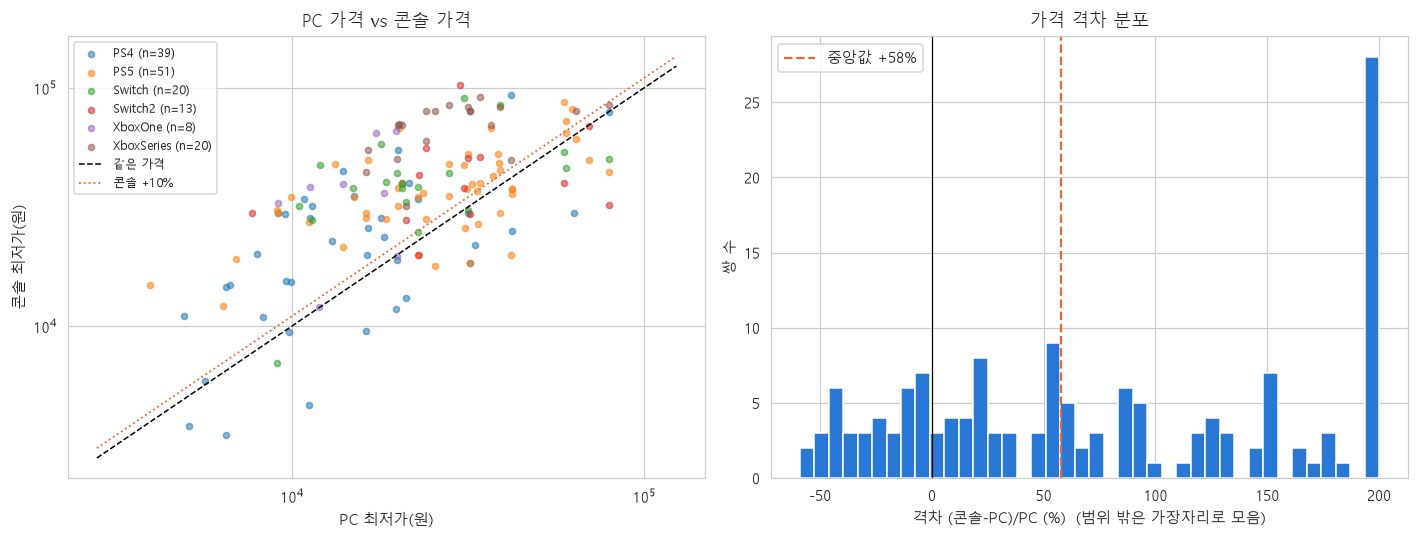

In [15]:
# PC 가격 vs 콘솔 가격 산점도 (로그 눈금). 점이 파선(같은 가격)보다 위에 있으면 콘솔이 더 비쌉니다.
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for plat, g in df.groupby('platform'):
    ax[0].scatter(g['pc_price_krw'], g['con_price_krw'], s=16, alpha=.55, label=f'{plat} (n={len(g)})')
lim = [df[['pc_price_krw', 'con_price_krw']].min().min() * .8, df[['pc_price_krw', 'con_price_krw']].max().max() * 1.2]
ax[0].plot(lim, lim, 'k--', lw=1, label='같은 가격')
ax[0].plot(lim, [v * (1 + PRACTICAL_GAP) for v in lim], color=ORANGE, ls=':', lw=1.2, label=f'콘솔 +{PRACTICAL_GAP:.0%}')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('PC 최저가(원)'); ax[0].set_ylabel('콘솔 최저가(원)')
ax[0].set_title('PC 가격 vs 콘솔 가격'); ax[0].legend(fontsize=8)
ax[1].hist(df['gap'].clip(-.75, 2) * 100, bins=40, color=BLUE)
ax[1].axvline(0, color='k', lw=.8); ax[1].axvline(df['gap'].median() * 100, color=ORANGE, ls='--', label=f"중앙값 {df['gap'].median():+.0%}")
ax[1].set_xlabel('격차 (콘솔-PC)/PC (%)  (범위 밖은 가장자리로 모음)'); ax[1].set_ylabel('쌍 수'); ax[1].set_title('가격 격차 분포'); ax[1].legend()
savefig(fig, 'a8_3_scatter.png'); plt.show()

### 차트 해설
왼쪽은 PC 가격(가로)과 콘솔 가격(세로)을 쌍마다 점으로 찍은 것(점선 = 같은 가격, 주황 점선 = 콘솔이 10% 비싼 선), 오른쪽은 격차(%)의 분포입니다.

### 이 차트로 알 수 있는 것
- 점이 점선 **위쪽에 몰려 있으면** 콘솔이 대체로 비싸다는 뜻입니다. 플랫폼(색)마다 위치가 다른지도 대략 보입니다.
- 오른쪽 분포가 0보다 오른쪽에 치우쳤는지, 얼마나 퍼져 있는지(게임마다 편차)를 봅니다. 분포가 넓으면 "평균적으로는 이렇다"가 모든 게임에 해당하지는 않는다는 뜻입니다.
- 가격이 PC 쪽으로 낮게 몰린 점이 보이면 **PC 할인**이 격차를 키웠을 가능성을 6~7장에서 확인합니다.

In [16]:
# 플랫폼별 · 출시 후 경과 기간별 격차의 요약표
print('■ 플랫폼별')
display(df.groupby('platform')['gap'].agg(쌍수='size', 중앙값='median', 평균='mean', 표준편차='std').sort_values('쌍수', ascending=False))
print('■ 출시 후 경과 기간별')
display(df.groupby('age_bin', observed=True)['gap'].agg(쌍수='size', 중앙값='median', 평균='mean', 표준편차='std'))

■ 플랫폼별


,쌍수,중앙값,평균,표준편차
platform,,,,
PS5,51,0.370,0.613,0.874
PS4,39,0.537,0.600,0.881
Switch,20,0.880,0.921,0.923
XboxSeries,20,1.578,1.517,0.788
Switch2,13,0.324,0.616,1.040
XboxOne,8,2.078,1.607,1.137


■ 출시 후 경과 기간별


,쌍수,중앙값,평균,표준편차
age_bin,,,,
1년 미만,4,0.250,0.721,1.150
1~2년,27,0.157,0.487,0.819
2~4년,43,0.897,1.028,1.067
4년 이상,77,0.607,0.832,0.911


## 6. 가설 검정

공통 도구를 먼저 정의합니다. (효과크기, 게임 단위 부트스트랩 신뢰구간, 판정 함수)

In [17]:
def cluster_ci(frame, col, stat=np.median, B=N_BOOT, seed=SEED):
    # 같은 게임의 쌍은 비슷하게 움직이므로, 게임을 단위로 다시 뽑아 신뢰구간을 구합니다.
    groups = {g: v[col].to_numpy() for g, v in frame.groupby('game_id')}
    keys = np.array(list(groups))
    rng = np.random.default_rng(seed)
    vals = [stat(np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])) for _ in range(B)]
    return np.percentile(vals, [2.5, 97.5])

def verdict(p, effect_ok, direction_ok=True):
    if direction_ok and p < ALPHA and effect_ok:
        return '✅ 가설과 일치 — 통계적으로 유의하고 효과도 실무 기준을 넘음'
    if direction_ok and p < ALPHA:
        return '⚠️ 부분 일치 — 통계적으로는 유의하나 효과가 실무 기준에 못 미침'
    return '❌ 불일치 — 귀무가설을 기각하지 못함(차이가 있다고 말할 근거 부족)'

def mark(ok):
    return {True: '✅ 일치', False: '❌ 불일치', None: '검정 안 함'}[ok]

### 6-1) H1. 콘솔 새 상품은 PC보다 비싼가?

**① 정규성 확인 → 도구 선택**: 격차가 정규분포가 아니면 t-검정 대신 순위 기반 **Wilcoxon 부호순위검정**(같은 게임의 PC·콘솔 가격 = 짝지은 자료, 단측)을 씁니다.
**② 독립성 확보**: 한 게임에 콘솔이 여러 개면 쌍이 독립이 아니므로, **게임마다 로그 격차의 중앙값 하나**로 요약한 뒤 검정합니다. (쌍 단위 결과는 참고로만 표시)

In [18]:
glvl = df.groupby('game_id').agg(log_ratio=('log_ratio', 'median'), gap=('gap', 'median')).reset_index()   # 게임당 한 값

sw = stats.shapiro(glvl['log_ratio'].to_numpy()[:5000])
print(f'Shapiro-Wilk 정규성 검정(게임 단위 로그 격차): W={sw.statistic:.3f}, p={sw.pvalue:.4f} →',
      '정규분포가 아님 → 비모수 검정 사용' if sw.pvalue < ALPHA else '정규성을 부정할 근거 없음(그래도 비모수 검정으로 보수적으로 확인)')

w_game = stats.wilcoxon(glvl['log_ratio'], alternative='greater')                      # 게임 단위 (주 검정)
w_pair = stats.wilcoxon(np.log(df['con_price_krw']), np.log(df['pc_price_krw']), alternative='greater')   # 쌍 단위 (참고)
lo, hi = cluster_ci(df, 'gap')
med_gap = float(np.median(glvl['gap']))
share_pc_cheaper = float((df['gap'] > 0).mean())

h1 = pd.DataFrame({'값': [len(glvl), len(df), f'{med_gap:+.1%}', f'{lo:+.1%} ~ {hi:+.1%}', f'{share_pc_cheaper:.0%}',
                          f'{w_game.pvalue:.2e}', f'{w_pair.pvalue:.2e}']},
                  index=['게임 수', '쌍 수', '격차 중앙값 (게임 단위)', '격차 중앙값 95% 신뢰구간(게임 단위 부트스트랩)', 'PC가 더 싼 쌍의 비율',
                         'Wilcoxon p (게임 단위, 주 검정)', 'Wilcoxon p (쌍 단위, 참고)'])
display(h1)
effect_ok = med_gap >= PRACTICAL_GAP and lo > 0
R['h1'] = dict(n_games=len(glvl), n_pairs=len(df), median_gap=med_gap, ci=[float(lo), float(hi)], share_pc_cheaper=share_pc_cheaper,
               p_game=float(w_game.pvalue), p_pair=float(w_pair.pvalue), ok=bool(w_game.pvalue < ALPHA and effect_ok))
print('\nH1 판정:', verdict(w_game.pvalue, effect_ok, direction_ok=med_gap > 0))

Shapiro-Wilk 정규성 검정(게임 단위 로그 격차): W=0.976, p=0.0715 → 정규성을 부정할 근거 없음(그래도 비모수 검정으로 보수적으로 확인)


,값
게임 수,97
쌍 수,151
격차 중앙값 (게임 단위),+66.1%
격차 중앙값 95% 신뢰구간(게임 단위 부트스트랩),+37.0% ~ +87.8%
PC가 더 싼 쌍의 비율,75%
"Wilcoxon p (게임 단위, 주 검정)",1.99e-11
"Wilcoxon p (쌍 단위, 참고)",1.69e-14



H1 판정: ✅ 가설과 일치 — 통계적으로 유의하고 효과도 실무 기준을 넘음


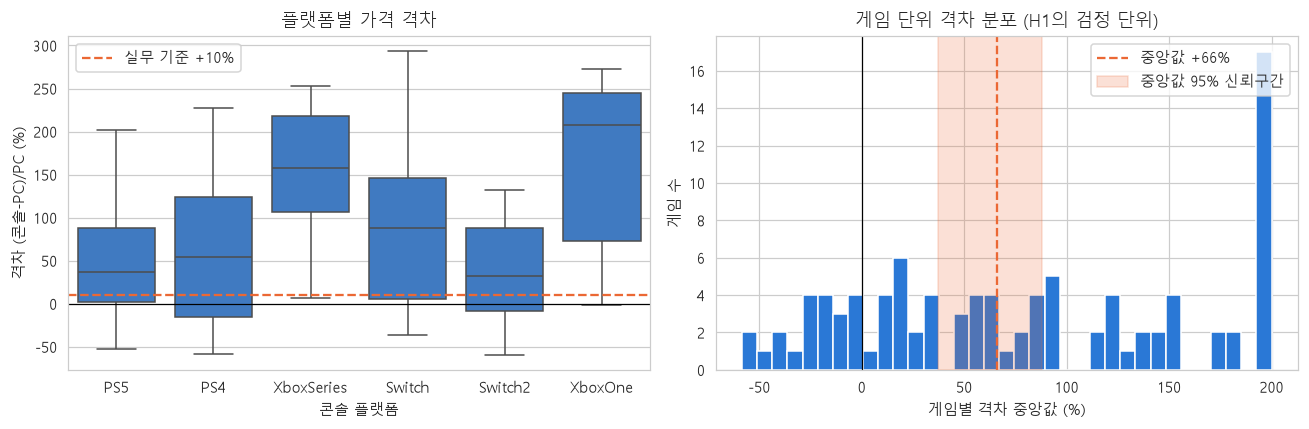

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='platform', y=df['gap'] * 100, color=BLUE, showfliers=False, ax=ax[0],
            order=df['platform'].value_counts().index)
ax[0].axhline(0, color='k', lw=.8); ax[0].axhline(PRACTICAL_GAP * 100, color=ORANGE, ls='--', label=f'실무 기준 +{PRACTICAL_GAP:.0%}')
ax[0].set_xlabel('콘솔 플랫폼'); ax[0].set_ylabel('격차 (콘솔-PC)/PC (%)'); ax[0].legend(); ax[0].set_title('플랫폼별 가격 격차')
ax[1].hist(glvl['gap'].clip(-.75, 2) * 100, bins=35, color=BLUE)
ax[1].axvline(0, color='k', lw=.8); ax[1].axvline(med_gap * 100, color=ORANGE, ls='--', label=f'중앙값 {med_gap:+.0%}')
ax[1].axvspan(lo * 100, hi * 100, color=ORANGE, alpha=.2, label='중앙값 95% 신뢰구간')
ax[1].set_xlabel('게임별 격차 중앙값 (%)'); ax[1].set_ylabel('게임 수'); ax[1].legend(); ax[1].set_title('게임 단위 격차 분포 (H1의 검정 단위)')
savefig(fig, 'a8_4_h1.png'); plt.show()

### 차트 해설
왼쪽은 콘솔 플랫폼별 격차 분포(상자그림), 오른쪽은 게임 한 개당 한 값으로 요약한 격차 분포입니다. 주황 음영은 중앙값의 95% 신뢰구간입니다.

### 이 차트로 알 수 있는 것
- 상자가 0선(검정)보다 위에 있고 주황 점선(+10%)을 넘으면 H1과 일치합니다.
- 음영(신뢰구간)이 0을 포함하지 않으면 "PC가 더 싸다"는 결론이 게임을 다시 뽑아도 유지된다는 뜻입니다.
- 분포가 0 양쪽으로 넓게 퍼져 있으면 *평균적으로는* 그렇지만 *게임에 따라 콘솔이 더 싼 경우도 많다*는 뜻이므로, 서비스에서는 "항상 PC가 싸다"가 아니라 "게임별 비교"를 보여 줘야 합니다.

### 6-2) H2. 출시 후 오래될수록 격차가 줄어드는가?

* **Spearman 상관**(단측, 음의 상관): 경과 기간이 길수록 격차가 작아지는가
* **Kruskal-Wallis**: 경과 기간 구간 사이에 차이가 있는가
* **구간별 Wilcoxon (Holm 보정)**: 각 구간의 격차가 0보다 큰가 (4개를 동시에 검정하므로 우연히 유의해지는 것을 Holm 방법으로 보정)
* **회귀분석 (OLS, 게임 단위 군집 표준오차)**: 플랫폼·PC 할인 여부·온라인 게임 여부를 **통제**한 뒤에도 경과 기간 효과가 남는가

In [20]:
rho, p_rho = stats.spearmanr(df['age_months'], df['gap'])
p_rho_one = p_rho / 2 if rho < 0 else 1 - p_rho / 2                         # 단측(음의 상관) p
groups = [g['gap'].to_numpy() for _, g in df.groupby('age_bin', observed=True) if len(g) >= MIN_N]
kw = stats.kruskal(*groups) if len(groups) >= 2 else None
print(f'Spearman 상관(경과 개월 ↔ 격차): rho={rho:.3f}, 단측 p={p_rho_one:.4f}')
print(f'Kruskal-Wallis(구간 간 차이): H={kw.statistic:.2f}, p={kw.pvalue:.4f}' if kw else 'Kruskal-Wallis: 표본이 충분한 구간이 2개 미만')

rows = []
for lab in AGE_LABELS:
    g = df[df['age_bin'] == lab]
    if len(g) < MIN_N:
        rows.append(dict(구간=lab, 쌍수=len(g), 중앙값=np.nan, 신뢰구간='표본 부족', p_0보다큼=np.nan)); continue
    lo_, hi_ = cluster_ci(g, 'gap', B=1000)
    rows.append(dict(구간=lab, 쌍수=len(g), 중앙값=g['gap'].median(), 신뢰구간=f'{lo_:+.0%} ~ {hi_:+.0%}',
                     p_0보다큼=stats.wilcoxon(g['gap'], alternative='greater').pvalue))
h2t = pd.DataFrame(rows)
ok_rows = h2t['p_0보다큼'].notna()
h2t.loc[ok_rows, 'p(Holm 보정)'] = multipletests(h2t.loc[ok_rows, 'p_0보다큼'], method='holm')[1]
display(h2t.round(4))

tested = h2t[ok_rows]
newest, oldest = (tested.iloc[0], tested.iloc[-1]) if len(tested) >= 2 else (None, None)
drop_pp = (newest['중앙값'] - oldest['중앙값']) if newest is not None else np.nan
below = tested[tested['중앙값'] < PRACTICAL_GAP]
first_cheap_bin = below.iloc[0]['구간'] if len(below) else None
if newest is not None:
    print(f'\n가장 새 구간({newest["구간"]}) → 가장 오래된 구간({oldest["구간"]}): 격차 중앙값이 {abs(drop_pp):.1%}p ' + ('줄어듦' if drop_pp > 0 else '오히려 늘어남(가설과 반대 방향)'))
print('격차 중앙값이 처음으로 +10% 아래로 내려가는 구간:', first_cheap_bin or '없음 (모든 구간에서 +10% 이상)')

Spearman 상관(경과 개월 ↔ 격차): rho=0.117, 단측 p=0.9231
Kruskal-Wallis(구간 간 차이): H=4.63, p=0.0985


,구간,쌍수,중앙값,신뢰구간,p_0보다큼,p(Holm 보정)
0,1년 미만,4,NaN,표본 부족,NaN,NaN
1,1~2년,27,0.157,+0% ~ +100%,0.004,0.004
2,2~4년,43,0.897,+39% ~ +150%,0.000,0.000
3,4년 이상,77,0.607,+52% ~ +97%,0.000,0.000



가장 새 구간(1~2년) → 가장 오래된 구간(4년 이상): 격차 중앙값이 45.0%p 오히려 늘어남(가설과 반대 방향)
격차 중앙값이 처음으로 +10% 아래로 내려가는 구간: 없음 (모든 구간에서 +10% 이상)


In [21]:
# 회귀분석: 격차(로그 비율)를 경과 기간·플랫폼·PC 할인 여부·온라인 여부로 설명. 게임 단위 군집 표준오차.
reg = df.copy()
reg['log_age'] = np.log1p(reg['age_months'])
reg['gid'] = pd.factorize(reg['game_id'])[0]
base_plat = reg['platform'].value_counts().idxmax()
model = smf.ols(f"log_ratio ~ log_age + C(platform, Treatment('{base_plat}')) + pc_on_sale + is_online", data=reg).fit(
    cov_type='cluster', cov_kwds={'groups': reg['gid']})
coef = pd.DataFrame({'계수': model.params, '표준오차': model.bse, 'p값': model.pvalues,
                     '95% 하한': model.conf_int()[0], '95% 상한': model.conf_int()[1]})
coef.index = [i.replace(f"C(platform, Treatment('{base_plat}'))[T.", '플랫폼=').replace(']', '') for i in coef.index]
display(coef.round(4))
print(f'기준 플랫폼: {base_plat}   /   R²={model.rsquared:.3f}   /   관측 {int(model.nobs)}쌍, 게임 {reg["gid"].nunique()}개')

b_age, p_age = model.params['log_age'], model.pvalues['log_age']
p_age_one = p_age / 2 if b_age < 0 else 1 - p_age / 2
h2_effect_ok = bool(newest is not None and drop_pp >= PRACTICAL_DIFF)
R['h2'] = dict(spearman_rho=float(rho), spearman_p_one=float(p_rho_one), kruskal_p=float(kw.pvalue) if kw else None,
               drop_pp=None if np.isnan(drop_pp) else float(drop_pp), first_below_practical=first_cheap_bin,
               reg_log_age=float(b_age), reg_log_age_p_one=float(p_age_one),
               table=h2t[['구간', '쌍수', '중앙값']].fillna(-999).to_dict('records'),
               ok=bool(p_rho_one < ALPHA and p_age_one < ALPHA and b_age < 0 and h2_effect_ok))
print('\nH2 판정(상관·회귀 모두 유의하고 구간 격차 감소가 5%p 이상이어야 일치):',
      verdict(max(p_rho_one, p_age_one), h2_effect_ok, direction_ok=(rho < 0 and b_age < 0)))

,계수,표준오차,p값,95% 하한,95% 상한
Intercept,-0.767,0.314,0.014,-1.382,-0.152
플랫폼=PS4,-0.192,0.124,0.120,-0.435,0.050
플랫폼=Switch,0.237,0.131,0.071,-0.020,0.494
플랫폼=Switch2,0.079,0.156,0.614,-0.227,0.385
플랫폼=XboxOne,0.383,0.160,0.017,0.069,0.696
플랫폼=XboxSeries,0.548,0.085,0.000,0.380,0.715
log_age,0.221,0.088,0.012,0.048,0.394
pc_on_sale,0.473,0.087,0.000,0.302,0.644
is_online,-0.215,0.096,0.025,-0.405,-0.026


기준 플랫폼: PS5   /   R²=0.266   /   관측 151쌍, 게임 97개

H2 판정(상관·회귀 모두 유의하고 구간 격차 감소가 5%p 이상이어야 일치): ❌ 불일치 — 귀무가설을 기각하지 못함(차이가 있다고 말할 근거 부족)


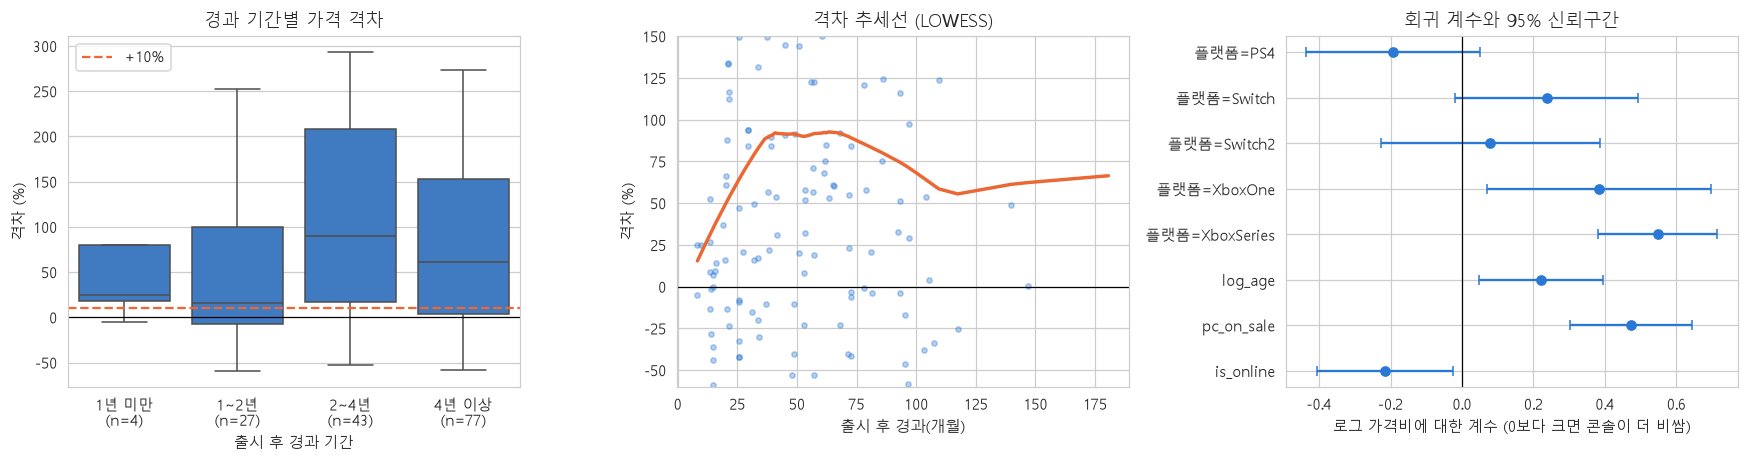

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sns.boxplot(data=df, x='age_bin', y=df['gap'] * 100, color=BLUE, showfliers=False, ax=ax[0], order=AGE_LABELS)
ax[0].axhline(0, color='k', lw=.8); ax[0].axhline(PRACTICAL_GAP * 100, color=ORANGE, ls='--', label=f'+{PRACTICAL_GAP:.0%}')
ax[0].set_xticks(range(len(AGE_LABELS))); ax[0].set_xticklabels([f"{l}\n(n={int((df['age_bin'] == l).sum())})" for l in AGE_LABELS])
ax[0].set_xlabel('출시 후 경과 기간'); ax[0].set_ylabel('격차 (%)'); ax[0].legend(); ax[0].set_title('경과 기간별 가격 격차')
ax[1].scatter(df['age_months'], df['gap'] * 100, s=12, alpha=.35, color=BLUE)
sns.regplot(data=df.assign(g=df['gap'] * 100), x='age_months', y='g', lowess=True, scatter=False, color=ORANGE, ax=ax[1])
ax[1].axhline(0, color='k', lw=.8); ax[1].set_ylim(-60, 150)
ax[1].set_xlabel('출시 후 경과(개월)'); ax[1].set_ylabel('격차 (%)'); ax[1].set_title('격차 추세선 (LOWESS)')
cf = coef.drop(index='Intercept')
ypos = np.arange(len(cf))[::-1]
ax[2].errorbar(cf['계수'], ypos, xerr=[cf['계수'] - cf['95% 하한'], cf['95% 상한'] - cf['계수']], fmt='o', color=BLUE, capsize=3)
ax[2].axvline(0, color='k', lw=.8); ax[2].set_yticks(ypos); ax[2].set_yticklabels(cf.index)
ax[2].set_xlabel('로그 가격비에 대한 계수 (0보다 크면 콘솔이 더 비쌈)'); ax[2].set_title('회귀 계수와 95% 신뢰구간')
savefig(fig, 'a8_5_h2.png'); plt.show()

### 차트 해설
왼쪽은 경과 기간 구간별 격차(상자그림, 아래 숫자는 쌍 수), 가운데는 경과 개월에 따른 격차 점과 추세선(LOWESS), 오른쪽은 회귀분석 계수와 95% 신뢰구간입니다.

### 이 차트로 알 수 있는 것
- 상자·추세선이 **오른쪽(오래된 게임)으로 갈수록 내려가면** H2와 일치합니다. 주황 점선(+10%) 아래로 처음 내려가는 구간이 "콘솔이 더 이상 크게 비싸지 않은 시점"입니다.
- 회귀 계수에서 `log_age`가 **0보다 작고 신뢰구간이 0을 지나지 않으면**, 플랫폼·PC 할인·온라인 여부를 통제한 뒤에도 경과 기간이 격차를 줄이는 것입니다. (단순 상관이 다른 요인 때문에 생긴 착시인지 구별하는 장치)
- `pc_on_sale`이 0보다 크면 **PC가 할인 중일 때 콘솔과의 격차가 더 벌어진다**는 뜻이어서, 격차의 상당 부분이 "콘솔이 비싸서"가 아니라 "PC 할인 때문"일 수 있습니다.

### 6-3) H3. 플랫폼마다 격차가 다른가?

**Kruskal-Wallis**로 플랫폼 전체의 차이를 보고, 차이가 있으면 **쌍별 Mann-Whitney U**(Holm 보정)로 어느 플랫폼끼리 다른지 봅니다. 표본이 `MIN_N`개 미만인 플랫폼은 뺍니다.

In [23]:
plat_n = df['platform'].value_counts()
use_plat = plat_n[plat_n >= MIN_N].index.tolist()
print('검정에 쓰는 플랫폼:', use_plat, '/ 제외(표본 부족):', plat_n[plat_n < MIN_N].index.tolist())
plat_tab = df[df['platform'].isin(use_plat)].groupby('platform')['gap'].agg(쌍수='size', 중앙값='median').sort_values('중앙값')
display(plat_tab)

if len(use_plat) >= 2:
    kw3 = stats.kruskal(*[df.loc[df['platform'] == p_, 'gap'] for p_ in use_plat])
    print(f'Kruskal-Wallis(플랫폼 간 차이): H={kw3.statistic:.2f}, p={kw3.pvalue:.4g}')
    pw = []
    for i, a in enumerate(use_plat):
        for b in use_plat[i + 1:]:
            pw.append(dict(비교=f'{a} vs {b}', 중앙값차이=df.loc[df['platform'] == a, 'gap'].median() - df.loc[df['platform'] == b, 'gap'].median(),
                           p=stats.mannwhitneyu(df.loc[df['platform'] == a, 'gap'], df.loc[df['platform'] == b, 'gap']).pvalue))
    pw = pd.DataFrame(pw)
    pw['p(Holm 보정)'] = multipletests(pw['p'], method='holm')[1]
    display(pw.round(4))
    spread = float(plat_tab['중앙값'].max() - plat_tab['중앙값'].min())
    h3_effect_ok = spread >= PRACTICAL_DIFF
    R['h3'] = dict(kruskal_p=float(kw3.pvalue), spread_pp=spread, cheapest=plat_tab.index[0], priciest=plat_tab.index[-1],
                   ok=bool(kw3.pvalue < ALPHA and h3_effect_ok))
    print('\nH3 판정:', verdict(kw3.pvalue, h3_effect_ok))
else:
    R['h3'] = None
    print('표본이 충분한 플랫폼이 2개 미만이라 H3는 검정하지 않습니다.')

검정에 쓰는 플랫폼: ['PS5', 'PS4', 'XboxSeries', 'Switch'] / 제외(표본 부족): ['Switch2', 'XboxOne']


,쌍수,중앙값
platform,,
PS5,51,0.370
PS4,39,0.537
Switch,20,0.880
XboxSeries,20,1.578


Kruskal-Wallis(플랫폼 간 차이): H=16.00, p=0.001132


,비교,중앙값차이,p,p(Holm 보정)
0,PS5 vs PS4,-0.167,0.942,0.942
1,PS5 vs XboxSeries,-1.207,0.000,0.002
2,PS5 vs Switch,-0.510,0.154,0.462
3,PS4 vs XboxSeries,-1.040,0.001,0.003
4,PS4 vs Switch,-0.343,0.215,0.462
5,XboxSeries vs Switch,0.697,0.026,0.103



H3 판정: ✅ 가설과 일치 — 통계적으로 유의하고 효과도 실무 기준을 넘음


### 표 해설
플랫폼별 격차 중앙값(작은 순)과 Kruskal-Wallis 결과, 그리고 플랫폼 쌍별 비교(Holm 보정 p값)입니다.

### 이 표로 알 수 있는 것
- 플랫폼 전체의 p가 0.05보다 작아도 **중앙값 차이가 5%p 미만이면 실무적으로는 같은 수준**으로 봅니다.
- 쌍별 표에서 보정 p가 작은 조합이 "실제로 다른 플랫폼"입니다. 표본이 적은 플랫폼은 차이가 커 보여도 우연일 수 있으므로 `쌍수`를 같이 읽습니다.

## 7. 이 결과는 의미가 있는가?

p값만으로 결론을 내리지 않고 네 가지를 함께 봅니다.

1. **통계적 유의성**: p < 0.05 (다중 비교는 Holm 보정)
2. **효과 크기**: 실무 기준(H1 +10%, H2·H3 5%p)을 넘는가
3. **신뢰구간**: 게임 단위 95% 신뢰구간이 0을 포함하지 않는가
4. **강건성**: 분석 조건(의심 쌍 제거 한도, PC 에디션, PC 할인 여부)을 바꿔도 결론이 유지되는가

그리고 격차가 "콘솔이 비싸서"인지 "PC가 할인 중이라서"인지도 분리해 봅니다.

,조건,게임수,격차_중앙값,p
0,기본 설정,97,0.661,0.000
1,의심 쌍 한도 2배,66,0.208,0.000
2,의심 쌍 한도 8배,127,1.436,0.000
3,"PC ""디지털"" 에디션만",85,0.639,0.000
4,PC가 할인 중이 아닌 쌍만,13,0.004,0.227
5,PC가 할인 중인 쌍만,84,0.797,0.000
6,온라인 게임 제외,50,0.749,0.000


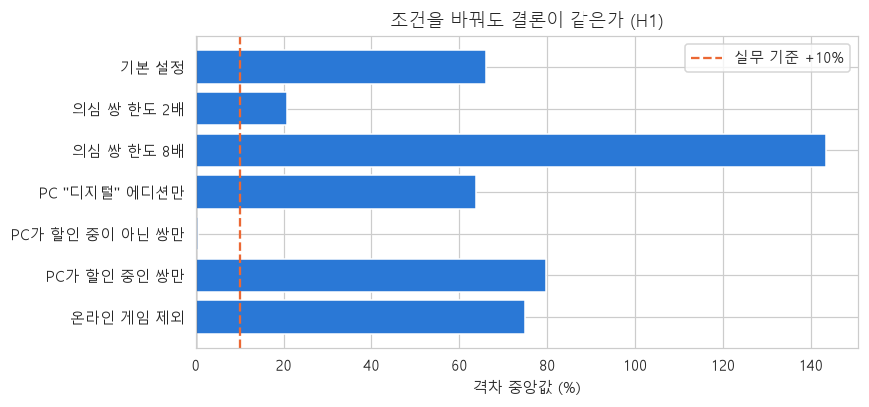

In [24]:
# 강건성 점검: 조건을 바꿔 H1 결과(격차 중앙값)가 유지되는지 봅니다.
def h1_stat(frame):
    g = frame.groupby('game_id')['gap'].median()
    if len(g) < 10:
        return dict(게임수=len(g), 격차_중앙값=np.nan, p=np.nan)
    return dict(게임수=len(g), 격차_중앙값=g.median(), p=stats.wilcoxon(np.log1p(g), alternative='greater').pvalue)

base = pairs[pairs['release_date'].notna()]
rows = [('기본 설정', h1_stat(df))]
for lim in (2.0, 8.0):
    rows.append((f'의심 쌍 한도 {lim:g}배', h1_stat(base[base['ratio'].between(1 / lim, lim)])))
rows.append(('PC "디지털" 에디션만', h1_stat(df[df['pc_edition'] == 'digital'])))
rows.append(('PC가 할인 중이 아닌 쌍만', h1_stat(df[df['pc_on_sale'] == 0])))
rows.append(('PC가 할인 중인 쌍만', h1_stat(df[df['pc_on_sale'] == 1])))
rows.append(('온라인 게임 제외', h1_stat(df[df['is_online'] == 0])))
sens = pd.DataFrame([dict(조건=k, **v) for k, v in rows])
display(sens)
R['sensitivity'] = sens.fillna(-999).to_dict('records')

fig, ax = plt.subplots(figsize=(8, 3.8))
s_ = sens.dropna(subset=['격차_중앙값'])
ax.barh(s_['조건'][::-1], s_['격차_중앙값'][::-1] * 100, color=BLUE)
ax.axvline(PRACTICAL_GAP * 100, color=ORANGE, ls='--', label=f'실무 기준 +{PRACTICAL_GAP:.0%}'); ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('격차 중앙값 (%)'); ax.set_title('조건을 바꿔도 결론이 같은가 (H1)'); ax.legend()
savefig(fig, 'a8_6_sensitivity.png'); plt.show()

### 차트 해설
조건을 바꿔 가며 같은 H1 분석(게임 단위 격차 중앙값)을 반복한 결과입니다.

### 이 차트로 알 수 있는 것
- 모든 막대가 주황 점선(+10%)을 넘으면 결과가 분석 설정에 좌우되지 않는 **강건한 결과**입니다.
- "PC가 할인 중이 아닌 쌍만"과 "할인 중인 쌍만"의 막대 차이가 크면, **PC 할인이 격차의 큰 부분을 만든다**는 뜻입니다. 이 경우 서비스 문구는 "콘솔이 비싸다"가 아니라 "지금 PC가 할인 중이라 싸다"가 정확합니다.

PC 정가를 아는 쌍: 150개


,쌍수,현재가대비_중앙값,정가대비_중앙값
PC 할인 중,,,
정가,23,0.084,0.084
할인 중,127,0.754,-0.388


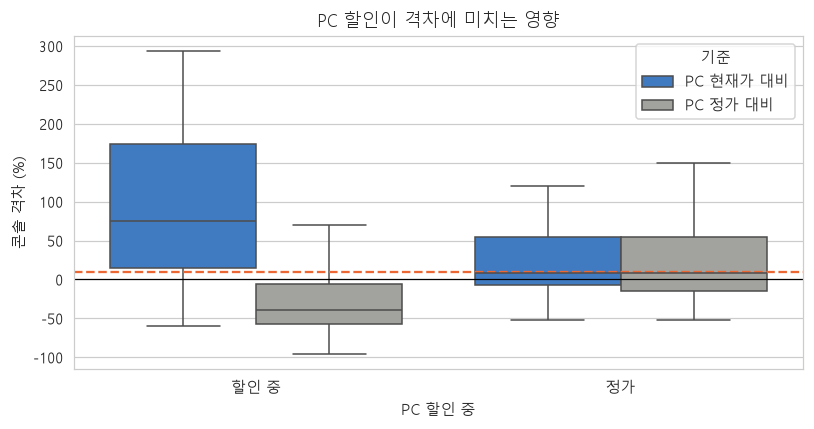

In [25]:
# PC 현재가(할인 반영) 대비 격차 vs PC 정가 대비 격차: PC 할인이 격차를 얼마나 키우는가
gg = df.dropna(subset=['gap_regular'])
cmp_ = pd.DataFrame({'PC 현재가 대비': gg['gap'], 'PC 정가 대비': gg['gap_regular'], 'PC 할인 중': gg['pc_on_sale'].map({1: '할인 중', 0: '정가'})})
print(f'PC 정가를 아는 쌍: {len(gg)}개')
display(cmp_.groupby('PC 할인 중').agg(쌍수=('PC 현재가 대비', 'size'), 현재가대비_중앙값=('PC 현재가 대비', 'median'), 정가대비_중앙값=('PC 정가 대비', 'median')))
R['regular'] = dict(median_vs_current=float(gg['gap'].median()), median_vs_regular=float(gg['gap_regular'].median()))

fig, ax = plt.subplots(figsize=(7.5, 4))
long = cmp_.melt(id_vars='PC 할인 중', var_name='기준', value_name='격차').assign(격차=lambda x: x['격차'] * 100)
sns.boxplot(data=long, x='PC 할인 중', y='격차', hue='기준', palette=[BLUE, GRAY], showfliers=False, ax=ax)
ax.axhline(0, color='k', lw=.8); ax.axhline(PRACTICAL_GAP * 100, color=ORANGE, ls='--'); ax.set_ylabel('콘솔 격차 (%)'); ax.set_title('PC 할인이 격차에 미치는 영향')
savefig(fig, 'a8_7_regular_vs_current.png'); plt.show()

### 차트 해설
PC가 지금 할인 중인 쌍과 정가인 쌍으로 나눠, 콘솔 가격을 **PC 현재가**와 **PC 정가** 두 기준으로 비교한 격차입니다.

### 이 차트로 알 수 있는 것
- 할인 중인 쌍에서 파란 상자(현재가 대비)가 회색 상자(정가 대비)보다 **훨씬 높으면**, 격차가 PC 할인 때문에 커 보이는 것입니다.
- 정가끼리 비교했을 때도 격차가 0보다 크면 "콘솔이 구조적으로 비싸다"고 말할 수 있고, 0 근처면 "할인이 없을 때는 비슷하다"가 됩니다.

In [26]:
# 가설별 최종 판정표
h1r, h2r, h3r = R['h1'], R['h2'], R['h3']
summary = pd.DataFrame([
    ['H1 콘솔 새 상품이 PC보다 비싸다', f"중앙값 {h1r['median_gap']:+.1%}", f"p={h1r['p_game']:.1e}", f"{h1r['ci'][0]:+.1%} ~ {h1r['ci'][1]:+.1%}", mark(h1r['ok'])],
    ['H2 오래될수록 격차가 줄어든다', f"rho={h2r['spearman_rho']:.2f}, 구간 간 감소폭 {h2r['drop_pp']:.1%}p" if h2r['drop_pp'] is not None else f"rho={h2r['spearman_rho']:.2f}",
     f"상관 p={h2r['spearman_p_one']:.1e}, 회귀 p={h2r['reg_log_age_p_one']:.1e}", '회귀 계수 표 참고', mark(h2r['ok'])],
    ['H3 플랫폼마다 격차가 다르다', f"최대−최소 {h3r['spread_pp']:+.1%}p" if h3r else '-', f"p={h3r['kruskal_p']:.1e}" if h3r else '-', '쌍별 표 참고', mark(h3r['ok'] if h3r else None)],
], columns=['가설', '핵심 값', '검정', '95% 신뢰구간', '판정'])
summary

,가설,핵심 값,검정,95% 신뢰구간,판정
0,H1 콘솔 새 상품이 PC보다 비싸다,중앙값 +66.1%,p=2.0e-11,+37.0% ~ +87.8%,✅ 일치
1,H2 오래될수록 격차가 줄어든다,"rho=0.12, 구간 간 감소폭 -45.0%p","상관 p=9.2e-01, 회귀 p=9.9e-01",회귀 계수 표 참고,❌ 불일치
2,H3 플랫폼마다 격차가 다르다,최대−최소 +120.7%p,p=1.1e-03,쌍별 표 참고,✅ 일치


## 8. 결론 — 가설 대비 결과와 인사이트·제안

아래 문장은 위 분석 결과를 **그대로 불러와** 만들어집니다. 판정이 "불일치"인 가설은 데이터가 지지하지 않는다고 발표에서 솔직하게 말하고, 제안은 일치한 부분만 근거로 삼습니다.

In [27]:
h1r, h2r, h3r, reg_r = R['h1'], R['h2'], R['h3'], R['regular']
L = []
L.append('■ 가설 대비 결과')
L.append(f"  H1 콘솔 > PC: {mark(h1r['ok'])}. 게임 {h1r['n_games']}개 기준 콘솔 새 상품이 PC 최저가보다 중앙값 {h1r['median_gap']:+.1%} "
         f"(95% 신뢰구간 {h1r['ci'][0]:+.1%}~{h1r['ci'][1]:+.1%}). PC가 더 싼 쌍은 {h1r['share_pc_cheaper']:.0%}.")
L.append(f"  H2 오래될수록 격차↓: {mark(h2r['ok'])}. 상관 rho={h2r['spearman_rho']:.2f}, 회귀(통제 후) 경과 계수 {h2r['reg_log_age']:+.3f} "
         f"(단측 p={h2r['reg_log_age_p_one']:.3f})" + (f", 가장 새 구간 대비 가장 오래된 구간의 격차 감소폭 {h2r['drop_pp']:.1%}p(음수면 오히려 커짐)." if h2r['drop_pp'] is not None else '.'))
if h3r:
    L.append(f"  H3 플랫폼별 차이: {mark(h3r['ok'])}. 가장 비싼 플랫폼 {h3r['priciest']}, 가장 싼 플랫폼 {h3r['cheapest']}, 중앙값 차이 {h3r['spread_pp']:.1%}p.")
else:
    L.append('  H3 플랫폼별 차이: 표본 부족으로 검정하지 않음.')

L.append('\n■ 구매 안내(서비스) 제안')
if h1r['ok']:
    L.append(f"  - 같은 게임이면 PC가 대체로 싸다(중앙값 {h1r['median_gap']:+.1%}). 상세 화면에 'PC가 콘솔보다 N% 저렴' 비교 표시를 제공.")
else:
    L.append('  - 콘솔이 PC보다 비싸다고 일반화할 근거가 부족. "PC가 싸다" 같은 일률적 문구는 쓰지 않고 게임별 실제 가격 비교만 보여 줌.')
if h2r['ok'] and h2r['first_below_practical']:
    L.append(f"  - 출시 [{h2r['first_below_practical']}] 구간부터는 격차 중앙값이 +10% 아래로 내려옴 → 신작은 PC 구매를 권하고, 그 이후에는 콘솔 패키지도 대안으로 안내.")
elif h2r['ok']:
    L.append('  - 격차는 시간이 갈수록 줄지만 모든 구간에서 +10% 이상 유지됨 → 오래된 게임도 콘솔 쪽이 비싸다는 점을 알림.')
else:
    L.append('  - 출시 후 경과 기간에 따른 격차 변화는 확인되지 않음 → "시간이 지나면 콘솔도 싸진다" 같은 안내는 하지 않음.')
if h3r and h3r['ok']:
    L.append(f"  - 플랫폼별로 격차가 다름: {h3r['priciest']}이(가) PC 대비 가장 비싸고 {h3r['cheapest']}이(가) 가장 작음 → 플랫폼별 배지/문구를 따로 둠.")
if reg_r['median_vs_current'] - reg_r['median_vs_regular'] > PRACTICAL_DIFF:
    L.append(f"  - 격차의 일부는 PC 할인 때문: PC 현재가 대비 {reg_r['median_vs_current']:+.1%} vs 정가 대비 {reg_r['median_vs_regular']:+.1%}. "
             "→ 문구는 '콘솔이 비싸다'보다 '지금 PC가 할인 중이라 싸다'가 정확.")

L.append('\n■ 데이터·파이프라인 시사점')
L.append(f"  - 분석 가능한 게임은 {R['n_games']}개 / 쌍 {R['n_pairs']}개. 이 수는 다나와 상품이 IGDB 게임에 연결된 정도에 달려 있으므로, 별칭(game_aliases) 보강으로 표본을 늘릴 수 있음.")
print('\n'.join(L))

(RESULT_DIR / 'summary.json').write_text(json.dumps(R, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
print('\n요약 저장:', RESULT_DIR / 'summary.json')

■ 가설 대비 결과
  H1 콘솔 > PC: ✅ 일치. 게임 97개 기준 콘솔 새 상품이 PC 최저가보다 중앙값 +66.1% (95% 신뢰구간 +37.0%~+87.8%). PC가 더 싼 쌍은 75%.
  H2 오래될수록 격차↓: ❌ 불일치. 상관 rho=0.12, 회귀(통제 후) 경과 계수 +0.221 (단측 p=0.994), 가장 새 구간 대비 가장 오래된 구간의 격차 감소폭 -45.0%p(음수면 오히려 커짐).
  H3 플랫폼별 차이: ✅ 일치. 가장 비싼 플랫폼 XboxSeries, 가장 싼 플랫폼 PS5, 중앙값 차이 120.7%p.

■ 구매 안내(서비스) 제안
  - 같은 게임이면 PC가 대체로 싸다(중앙값 +66.1%). 상세 화면에 'PC가 콘솔보다 N% 저렴' 비교 표시를 제공.
  - 출시 후 경과 기간에 따른 격차 변화는 확인되지 않음 → "시간이 지나면 콘솔도 싸진다" 같은 안내는 하지 않음.
  - 플랫폼별로 격차가 다름: XboxSeries이(가) PC 대비 가장 비싸고 PS5이(가) 가장 작음 → 플랫폼별 배지/문구를 따로 둠.
  - 격차의 일부는 PC 할인 때문: PC 현재가 대비 +59.1% vs 정가 대비 -32.7%. → 문구는 '콘솔이 비싸다'보다 '지금 PC가 할인 중이라 싸다'가 정확.

■ 데이터·파이프라인 시사점
  - 분석 가능한 게임은 97개 / 쌍 151개. 이 수는 다나와 상품이 IGDB 게임에 연결된 정도에 달려 있으므로, 별칭(game_aliases) 보강으로 표본을 늘릴 수 있음.

요약 저장: ..\results\a8\summary.json


### 한계 (발표에서 먼저 밝힐 것)
| 한계 | 영향 | 대응 |
| --- | --- | --- |
| **같은 상품이 아닐 수 있다**: PC는 디지털 다운로드·키 판매점 최저가, 콘솔은 다나와의 **패키지 최저가** | 격차에 "유통 형태 차이"가 섞임 | 7장에서 PC 디지털 에디션만으로 재확인. 발표에서 "비교 가능한 가장 싼 새 상품 기준"이라고 명시 |
| **현재 시점 가격(스냅샷)** | 가격은 매일 바뀜 → 오늘 한 번의 비교일 뿐 | 이력 기반 분석(A1)과 구분해서 말함. 결과 날짜를 함께 표기 |
| 다나와 상품 ↔ 게임 연결 오류 가능성 | 격차 왜곡 | 가격비 4배 초과 쌍 제거, 제외 목록을 눈으로 확인(4장), 한도를 바꿔 민감도 확인(7장) |
| PC·콘솔 **둘 다 있는 게임만** 비교 가능 | 콘솔 독점·PC 독점 게임은 제외, 표본 선택 편향 | 표본 수를 항상 같이 표기 |
| 콘솔 정가·할인 정보 없음 | 콘솔은 현재 최저가만 비교 | PC 정가 대비 격차를 보조로 제시 |
| 상관·회귀는 "함께 나타난다"이지 원인이 아님 | 경과 기간 효과가 재고·입고 시점 등 다른 요인일 수 있음 | 회귀로 일부 요인 통제, 해석은 "경향" 수준으로 |